In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="Lpym5135dTOtmIp4LQQC")
project = rf.workspace("fatima-laloa").project("hand-pointing-directions-lwomu")
version = project.version(2)
dataset = version.download("yolo26")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 76.4 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Hand-Pointing-Directions-2 in yolo26:: 100%|██████████| 1606/1606 [00:00<00:00, 6605.81it/s]


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from roboflow import Roboflow
import os

In [3]:
images_train = os.listdir("/content/Hand-Pointing-Directions-2/train/images")
len(images_train)

562

In [4]:
images_val = os.listdir("/content/Hand-Pointing-Directions-2/valid/images")
len(images_val)

160

In [5]:
images_test = os.listdir("/content/Hand-Pointing-Directions-2/test/images")
len(images_test)

79

In [6]:
from collections import Counter

In [7]:
import pandas as pd
import glob

labels = glob.glob("/content/Hand-Pointing-Directions-2/train/labels/*.txt")

classes = []

for file in labels:
    for line in open(file):
        if line.strip():
            classes.append(int(line.split()[0]))

pd.Series(classes).value_counts().sort_index()

,count
0,195
1,197
2,167


In [8]:
!pip install ultralytics
from ultralytics import YOLO

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [9]:
model = YOLO("yolo26s.pt")

In [29]:
model.train(data = "/content/Hand-Pointing-Directions-2/data.yaml",
    epochs=100,
    imgsz=640,
    fliplr=0.0,
    flipud=0.0,
    patience=20)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Hand-Pointing-Directions-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train-2/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d9d988bfaf0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04


image 1/1 /content/Hand-Pointing-Directions-2/test/images/IMG-20240318-WA0001_jpg.rf.bced48805b6eb87e74780e9f228e4e05.jpg: 640x480 1 Up, 9.7ms
Speed: 1.6ms preprocess, 9.7ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


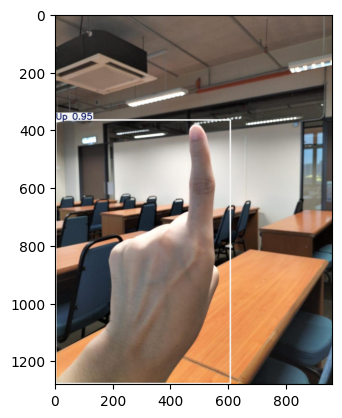

In [30]:
fintuned_model = YOLO("/content/runs/detect/train-3/weights/best.pt")

results = fintuned_model("/content/Hand-Pointing-Directions-2/test/images/IMG-20240318-WA0001_jpg.rf.bced48805b6eb87e74780e9f228e4e05.jpg")
plt.imshow(results[0].plot()[...,::-1])

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1466.6±947.2 MB/s, size: 63.5 KB)
val: Scanning /content/Hand-Pointing-Directions-2/test/labels.cache... 79 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 79/79 27.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1it/s 2.4s
                   all         79         79      0.999          1      0.995      0.991
                  Left         31         31      0.998          1      0.995       0.99
                 Right         29         29          1          1      0.995      0.988
                    Up         19         19          1          1      0.995      0.995
Speed: 3.9ms preprocess, 8.0ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /content/runs/detect/

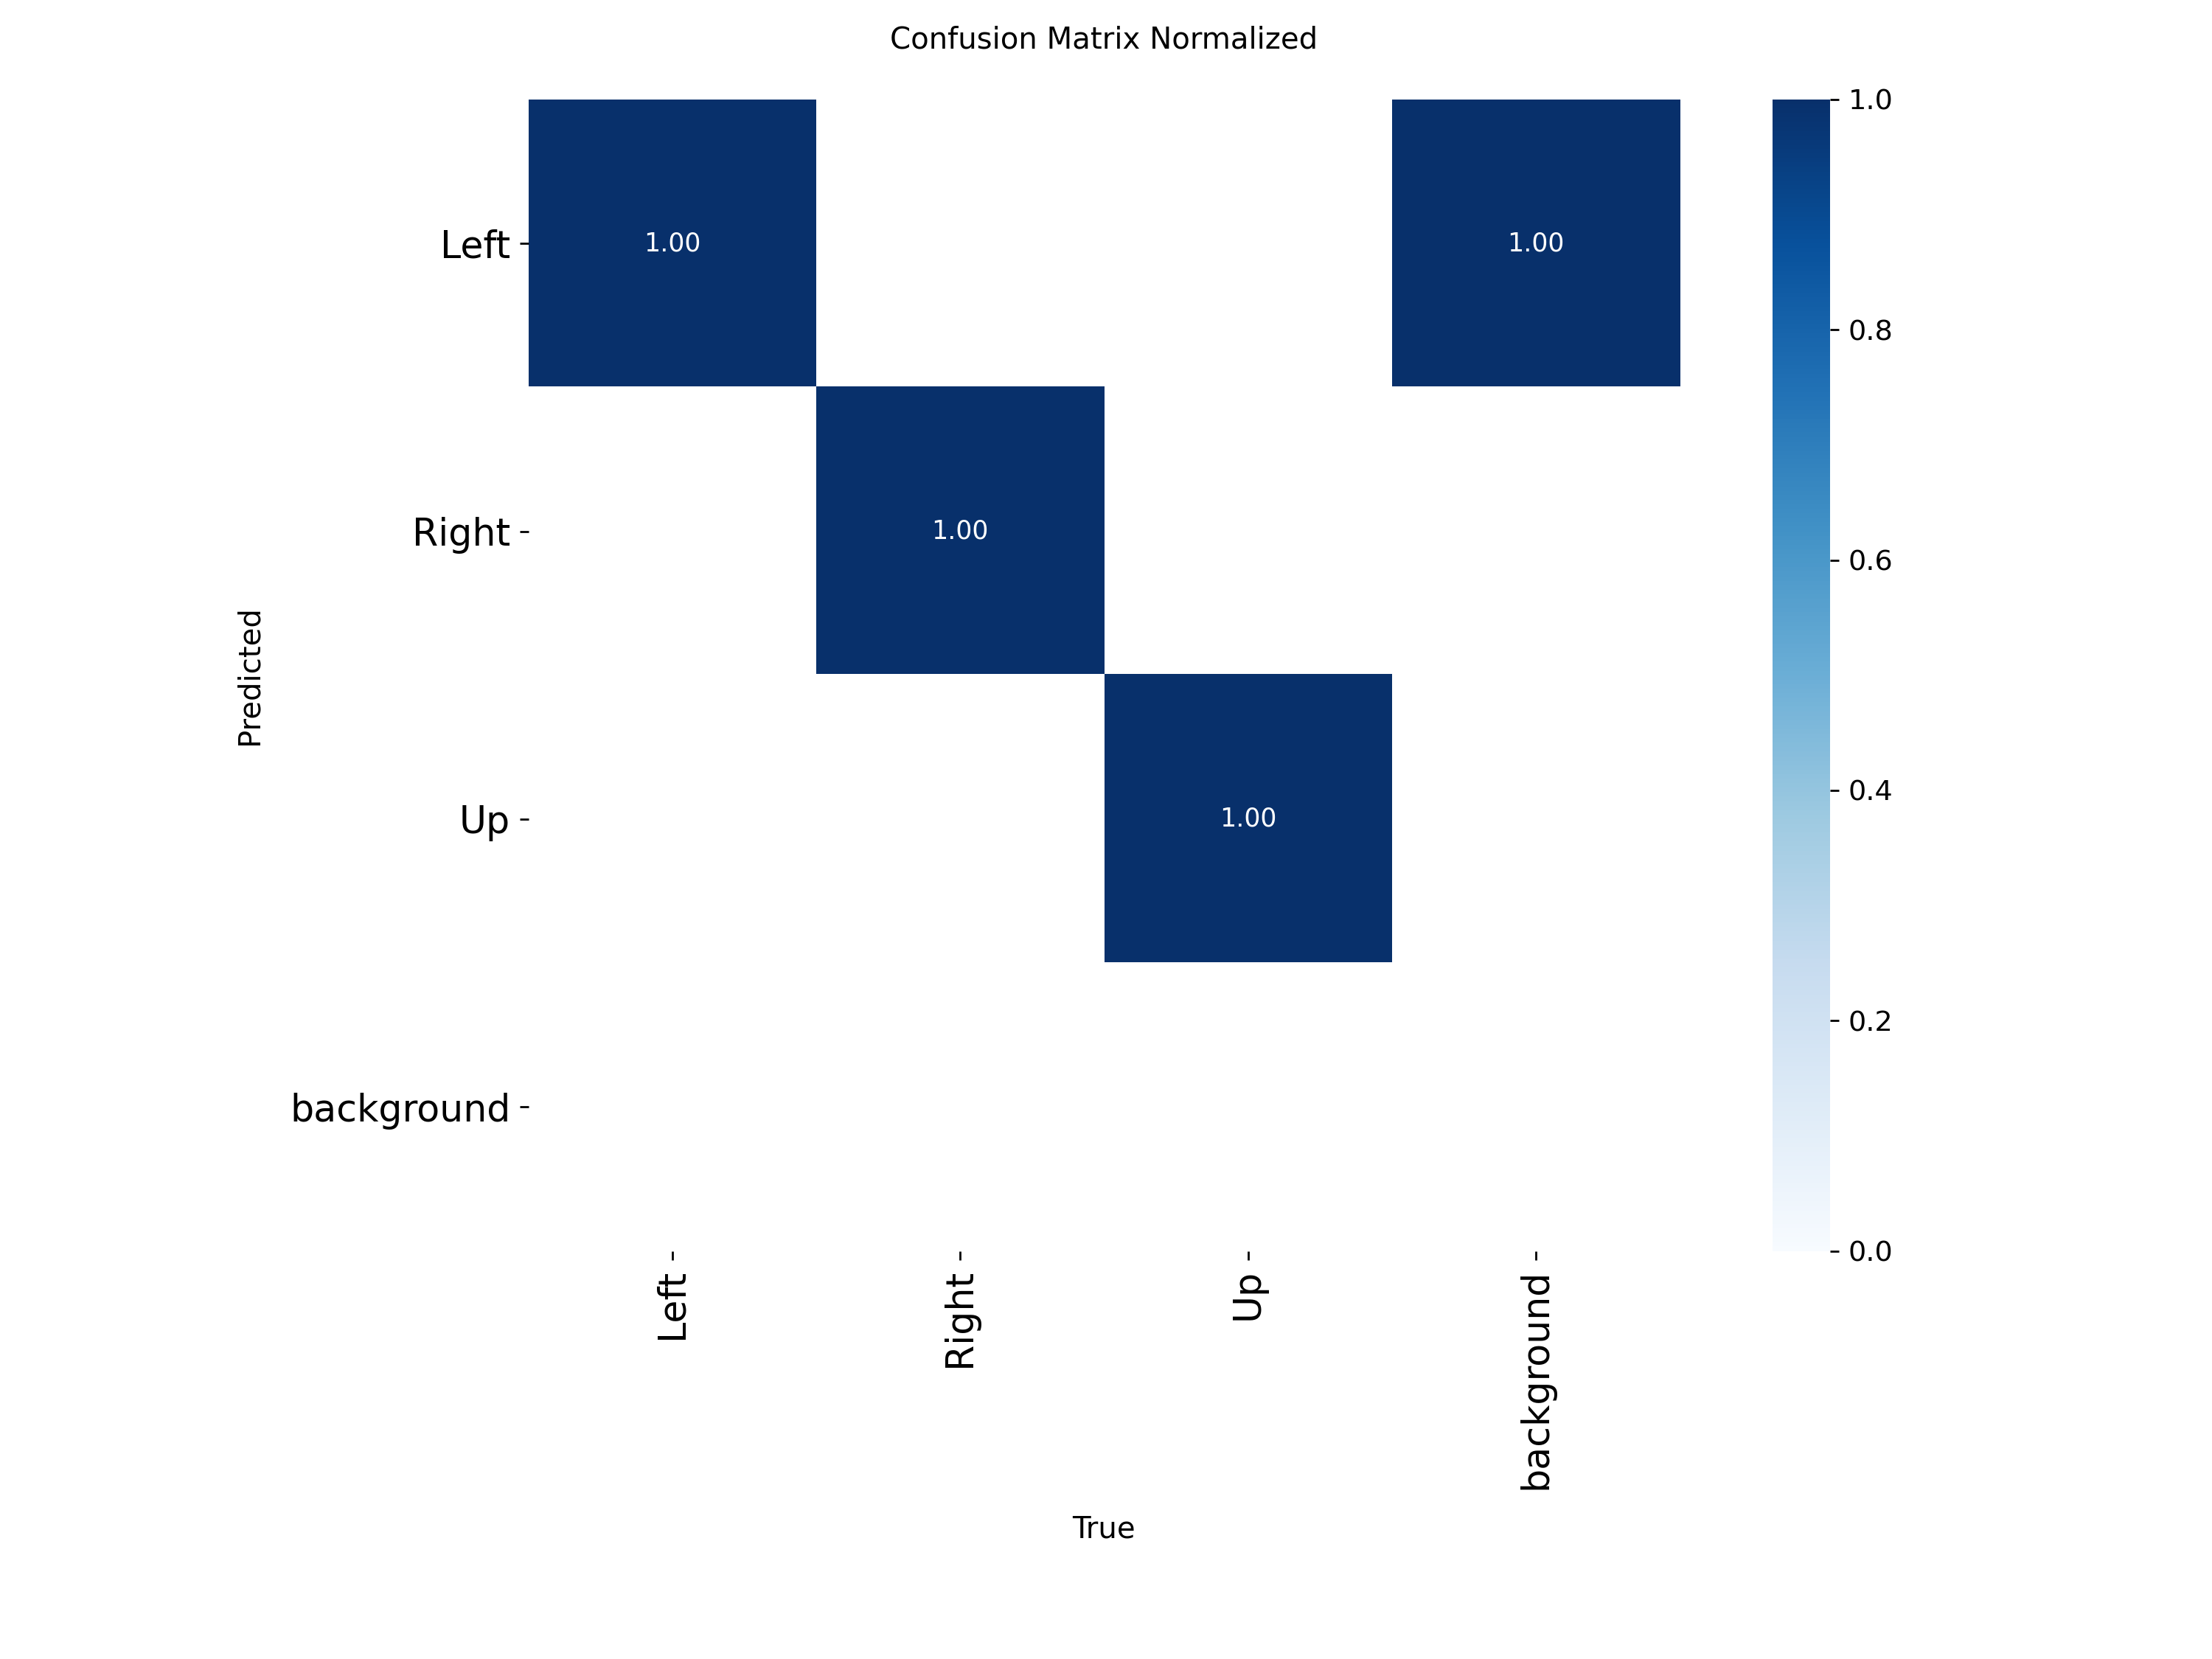

In [31]:
## Evaluation
from IPython.display import Image, display
# per class performance
metrics = fintuned_model.val(data="/content/Hand-Pointing-Directions-2/data.yaml", split="test")
# precision
print("Precision:", metrics.box.mp)
# recall
print("Recall:", metrics.box.mr)
# confision matrix
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png"))

In [2]:
import matplotlib.pyplot as plt

wrong = []
for r in fintuned_model.predict("/content/Hand-Pointing-Directions-2/test/images", stream=True, verbose=False):
    lbl = r.path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    true = sorted(r.names[int(l.split()[0])] for l in open(lbl))
    pred = sorted(r.names[int(c)] for c in r.boxes.cls)
    if true != pred:
        wrong.append((r.plot()[..., ::-1], f"True: {true}\nPred: {pred}"))

fig, axes = plt.subplots(4, 3, figsize=(5, 5))
for ax, (img, title) in zip(axes.flat, wrong[:9]):
    ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis("off")
plt.savefig("wrong_predictions.png")

NameError: name 'fintuned_model' is not defined